In [ ]:
import pandas as pd
df = pd.read_csv('superstore_orders_exp7.csv')
df['Order Date'] = pd.to_datetime(df['Order Date'])
monthly = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()
monthly.index = monthly.index.to_timestamp()
monthly.head(12)

,Sales
Order Date,
2023-01-01,14518.0550
2023-02-01,4519.8920
2023-03-01,56933.9090
2023-04-01,28295.3450
2023-05-01,26319.7670
2023-06-01,34669.4796
2023-07-01,33946.3930
2023-08-01,28918.3385
2023-09-01,82670.4288


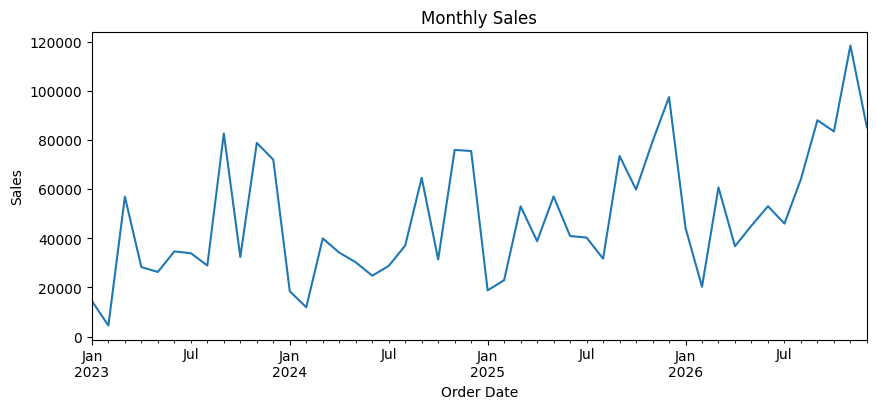

In [ ]:
import matplotlib.pyplot as plt
monthly.plot(figsize=(10,4), title='Monthly Sales')
plt.ylabel('Sales'); plt.show()

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
model = ExponentialSmoothing(monthly, trend='add',
                             seasonal='add',
seasonal_periods=12).fit()

In [ ]:
forecast = model.forecast(6)
forecast

,0
2027-01-01,51136.690711
2027-02-01,43082.472301
2027-03-01,77517.079683
2027-04-01,62980.733870
2027-05-01,70408.337233
2027-06-01,67039.266031


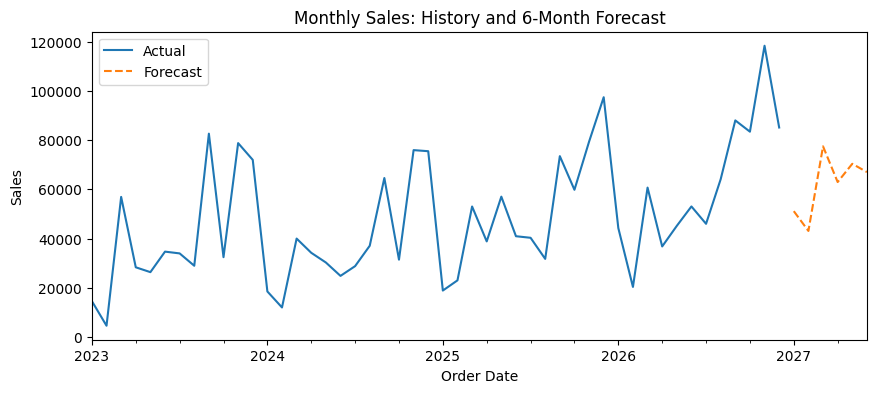

In [ ]:
plt.figure(figsize=(10,4))
monthly.plot(label='Actual')
forecast.plot(label='Forecast', style='--')
plt.legend(); plt.ylabel('Sales')
plt.title('Monthly Sales: History and 6-Month Forecast')
plt.show()

In [ ]:
train = monthly.iloc[:-6]
test = monthly.iloc[-6:]
m2 = ExponentialSmoothing(train, trend='add', seasonal='add',
seasonal_periods=12).fit()
pred = m2.forecast(6)
mape = (abs(test - pred) / test).mean() * 100
print('MAPE:', round(mape, 1), '%')

MAPE: 16.1 %
